# Computational Exercise 7

A finite element code written from scratch (no Firedrake, no UFL) for $P_1$ elements on $\Omega=[0,1]^2$.

| file | contents |
|---|---|
| `mesh.py` | `DoF`, `Element` (affine map $F_K(\hat x)=B_K\hat x+b_K$, $|\det B_K|$, $B_K^{-1}$), `Mesh` (connectivity, `CG1`/`DG1` numbering, boundary DoFs), `Function` (coefficients, plots) |
| `quadrature.py` | Strang-Fix rules on the master triangle |
| `solve_projection.py` | $P_1$ basis on the master element, local/global sparse assembly, $L^2$ and $H^1$ projections, errors |
| `solve_elliptic.py` | solver for $-\nabla\cdot(\mu\nabla u)+\sigma u=f$ with mixed boundary conditions |
| `test_fem.py` | automatic checks (`pytest test_fem.py`) |
| `check_vs_firedrake.py` | comparison with Firedrake (verification only) |

Everything is computed on the master element: $\int_K g\,dx=|\det B_K|\int_{\hat K}g(F_K(\hat x))\,d\hat x$ and $\nabla\phi=B_K^{-T}\hat\nabla\hat\phi$. Local matrices are added into a global `lil_matrix` that is converted to CSR before solving.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from mesh import Mesh, Function
from quadrature import Quadrature
from solve_projection import L2_projection, H1_projection, L2_error, H1_error
from solve_elliptic import solve_elliptic

plt.rcParams["figure.dpi"] = 110

## Checks of the building blocks

* Each quadrature rule integrates exactly all monomials up to the degree it was designed for (`test_fem.py`).
* All cells have $\det B_K>0$ and the areas add up to 1; the DoF counts are $(N+1)^2$ for `CG1` and $3\cdot 2N^2$ for `DG1`.
* Both projections reproduce a $P_1$ function to round-off.

In [3]:
print(f"{'N':>3} {'cells':>6} {'CG1 dofs':>9} {'DG1 dofs':>9}")
for N in (4, 8, 16):
    cg, dg = Mesh.UnitarySquareMesh(N, N, "CG1"), Mesh.UnitarySquareMesh(N, N, "DG1")
    print(f"{N:>3} {len(cg.elements):>6} {cg.num_dofs:>9} {dg.num_dofs:>9}")

lin = lambda x: 1 + 2*x[0] - 3*x[1]
glin = lambda x: np.array([2.0, -3.0])
for space, proj in (("DG1", L2_projection), ("CG1", L2_projection), ("CG1", H1_projection)):
    m = Mesh.UnitarySquareMesh(6, 6, space)
    uh = Function(m); proj(uh, lin, glin)
    print(f"{space} {proj.__name__}: error for a P1 function = {L2_error(uh, lin):.1e}")

  N  cells  CG1 dofs  DG1 dofs
  4     32        25        96
  8    128        81       384
 16    512       289      1536
DG1 L2_projection: error for a P1 function = 3.0e-16
CG1 L2_projection: error for a P1 function = 3.1e-16
CG1 H1_projection: error for a P1 function = 4.7e-15


## Projections

The projection $P_hu\in V_h$ satisfies $(P_hu,v_h)=(u,v_h)$ for all $v_h\in V_h$ with $(\cdot,\cdot)$ the $L^2$ or $H^1$ inner product. With $v_h=\phi_J$ this is $Ac=F$:

$$A_{IJ}=\int_\Omega\phi_I\phi_J\ \Big(+\int_\Omega\nabla\phi_I\cdot\nabla\phi_J\Big),\qquad F_I=\int_\Omega u\,\phi_I\ \Big(+\int_\Omega\nabla u\cdot\nabla\phi_I\Big).$$

**Why is the $H^1$ projection used only with the continuous space?** The $H^1$ inner product needs the weak gradient of the functions of $V_h$. Continuous piecewise polynomials belong to $H^1(\Omega)$, so $(\cdot,\cdot)_{H^1}$ is an inner product on the `CG1` space. A discontinuous $P_1$ function jumps across element edges; its distributional gradient has a Dirac measure on every edge, so it is not in $H^1$ and the cell-wise gradient would silently ignore those jumps. The $L^2$ projection only requires integrability and works in both spaces. The code raises an error for `H1_projection` on `DG1`.

Test function: $u(x,y)=\sin(2\pi x)\sin(2\pi y)$. The error is measured with the same 13-point quadrature rule; it is exact for polynomials of degree 7, far below the discretisation error.

In [4]:
u = lambda x: np.sin(2*np.pi*x[0]) * np.sin(2*np.pi*x[1])
grad_u = lambda x: np.array([2*np.pi*np.cos(2*np.pi*x[0])*np.sin(2*np.pi*x[1]),
                             2*np.pi*np.sin(2*np.pi*x[0])*np.cos(2*np.pi*x[1])])

Ns = [4, 8, 16, 32, 64, 128]
hs = []
err = {k: [] for k in ("DG1 L2-proj, L2 err", "CG1 L2-proj, L2 err",
                       "CG1 H1-proj, L2 err", "CG1 H1-proj, H1 err")}
for N in Ns:
    dg, cg = Mesh.UnitarySquareMesh(N, N, "DG1"), Mesh.UnitarySquareMesh(N, N, "CG1")
    hs.append(cg.h)
    uh = Function(dg); L2_projection(uh, u)
    err["DG1 L2-proj, L2 err"].append(L2_error(uh, u))
    uh = Function(cg); L2_projection(uh, u)
    err["CG1 L2-proj, L2 err"].append(L2_error(uh, u))
    uh = Function(cg); H1_projection(uh, u, grad_u)
    err["CG1 H1-proj, L2 err"].append(L2_error(uh, u))
    err["CG1 H1-proj, H1 err"].append(H1_error(uh, u, grad_u))

hs = np.array(hs)
print(f"{'N':>4} " + " ".join(f"{k:>22}" for k in err))
for i, N in enumerate(Ns):
    print(f"{N:>4} " + " ".join(f"{err[k][i]:>22.3e}" for k in err))
print("\nobserved rates between consecutive meshes:")
for k, v in err.items():
    v = np.array(v)
    print(f"{k:>22}:", np.round(np.log2(v[:-1]/v[1:]), 2))

   N    DG1 L2-proj, L2 err    CG1 L2-proj, L2 err    CG1 H1-proj, L2 err    CG1 H1-proj, H1 err
   4              7.310e-02              1.288e-01              1.931e-01              2.701e+00
   8              1.949e-02              2.883e-02              7.009e-02              1.606e+00
  16              4.950e-03              6.638e-03              1.965e-02              8.513e-01
  32              1.243e-03              1.620e-03              5.073e-03              4.332e-01
  64              3.110e-04              4.025e-04              1.280e-03              2.177e-01
 128              7.776e-05              1.005e-04              3.206e-04              1.090e-01

observed rates between consecutive meshes:
   DG1 L2-proj, L2 err: [1.91 1.98 1.99 2.   2.  ]
   CG1 L2-proj, L2 err: [2.16 2.12 2.03 2.01 2.  ]
   CG1 H1-proj, L2 err: [1.46 1.83 1.95 1.99 2.  ]
   CG1 H1-proj, H1 err: [0.75 0.92 0.97 0.99 1.  ]


### Error as a function of $h$ ($h=\sqrt2/N$, the cell diameter)

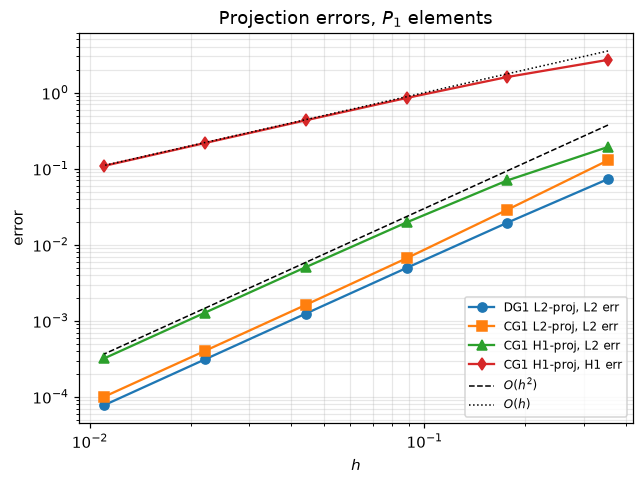

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 4.6))
styles = ["o-", "s-", "^-", "d-"]
for (k, v), st in zip(err.items(), styles):
    ax.loglog(hs, v, st, label=k)
ax.loglog(hs, 3*hs**2, "k--", lw=1, label="$O(h^2)$")
ax.loglog(hs, 10*hs, "k:", lw=1, label="$O(h)$")
ax.set_xlabel("$h$"); ax.set_ylabel("error"); ax.grid(True, which="both", alpha=.3)
ax.legend(fontsize=8); ax.set_title("Projection errors, $P_1$ elements")
plt.show()

### Contours of the projections ($N=8$)

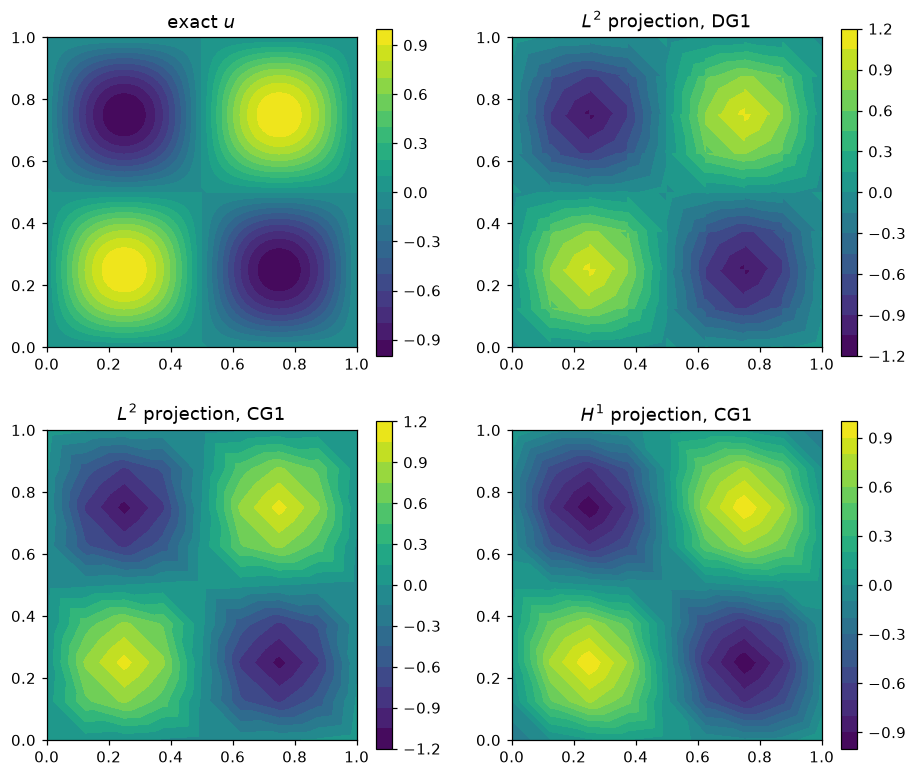

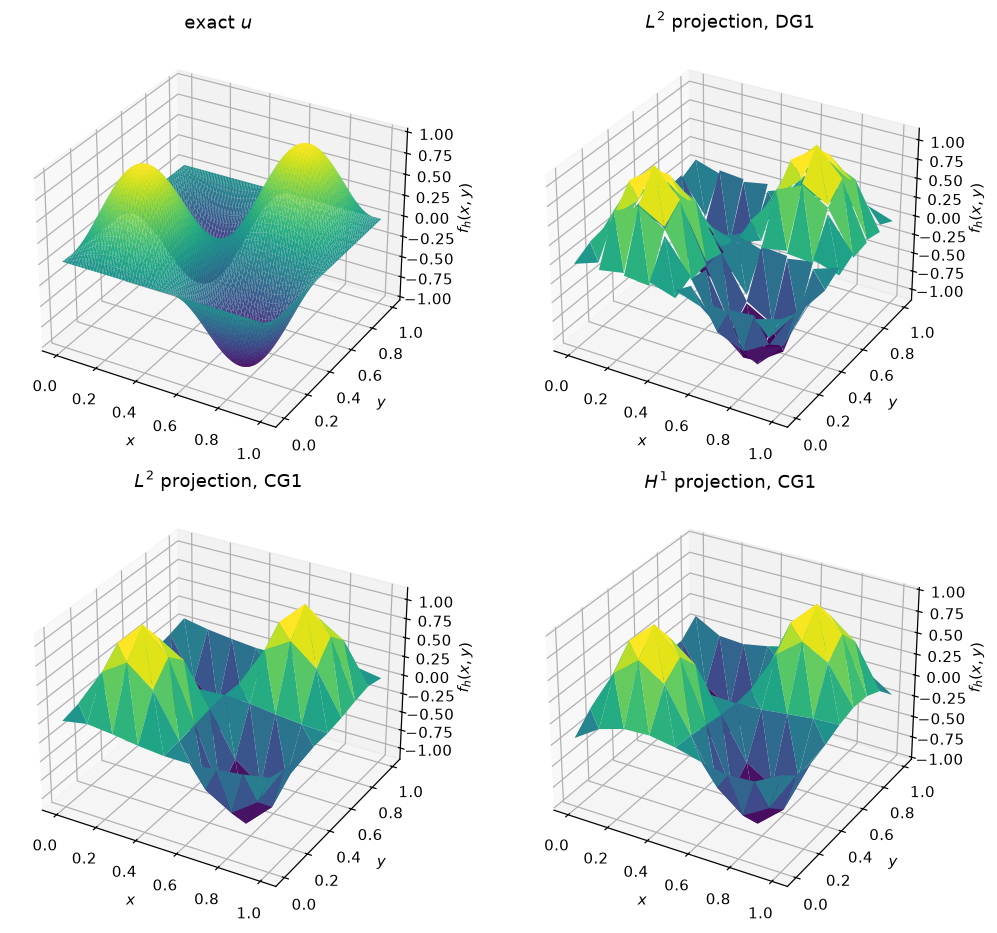

In [8]:
N = 8
dg, cg = Mesh.UnitarySquareMesh(N, N, "DG1"), Mesh.UnitarySquareMesh(N, N, "CG1")
fine = Mesh.UnitarySquareMesh(64, 64, "CG1")

ue = Function(fine); ue.coeffs = np.array([u(d.pos) for _, d in sorted(ue.dofs.items())])
u_dg = Function(dg); L2_projection(u_dg, u)
u_l2 = Function(cg); L2_projection(u_l2, u)
u_h1 = Function(cg); H1_projection(u_h1, u, grad_u)

fig, axs = plt.subplots(2, 2, figsize=(10, 8.5))
ue.plot_contour(axs[0, 0], title="exact $u$")
u_dg.plot_contour(axs[0, 1], title="$L^2$ projection, DG1")
u_l2.plot_contour(axs[1, 0], title="$L^2$ projection, CG1")
u_h1.plot_contour(axs[1, 1], title="$H^1$ projection, CG1")

fig2, axs2 = plt.subplots(2, 2, figsize=(10, 8.5), subplot_kw=dict(projection="3d"))
ue.plot_surface(axs2[0, 0], title="exact $u$")
u_dg.plot_surface(axs2[0, 1], title="$L^2$ projection, DG1")
u_l2.plot_surface(axs2[1, 0], title="$L^2$ projection, CG1")
u_h1.plot_surface(axs2[1, 1], title="$H^1$ projection, CG1")
plt.tight_layout(); plt.show()

## The problem $-\nabla\cdot(\mu\nabla u)+\sigma u=f$

Weak form: find $u_h=g$ on $\Gamma_D$ with $\int_\Omega\mu\nabla u_h\cdot\nabla v_h+\sigma u_hv_h=\int_\Omega fv_h$ for all $v_h$ vanishing on $\Gamma_D$. The condition $-\mu\nabla u\cdot\check n=0$ on $\Gamma_N$ is natural: nothing is imposed there. Dirichlet data are imposed by lifting: the boundary DoFs get the value $g$, the corresponding columns of $A$ go to the right-hand side and the reduced system for the remaining DoFs is solved. $\mu,\sigma,f$ are evaluated at the physical quadrature points $F_K(\hat x_g)$.

Note on case 1: with $\Gamma_D=\emptyset$ the problem is a pure Neumann problem, which is well posed here only because $\sigma=1>0$ (the matrix is stiffness + mass, hence positive definite).

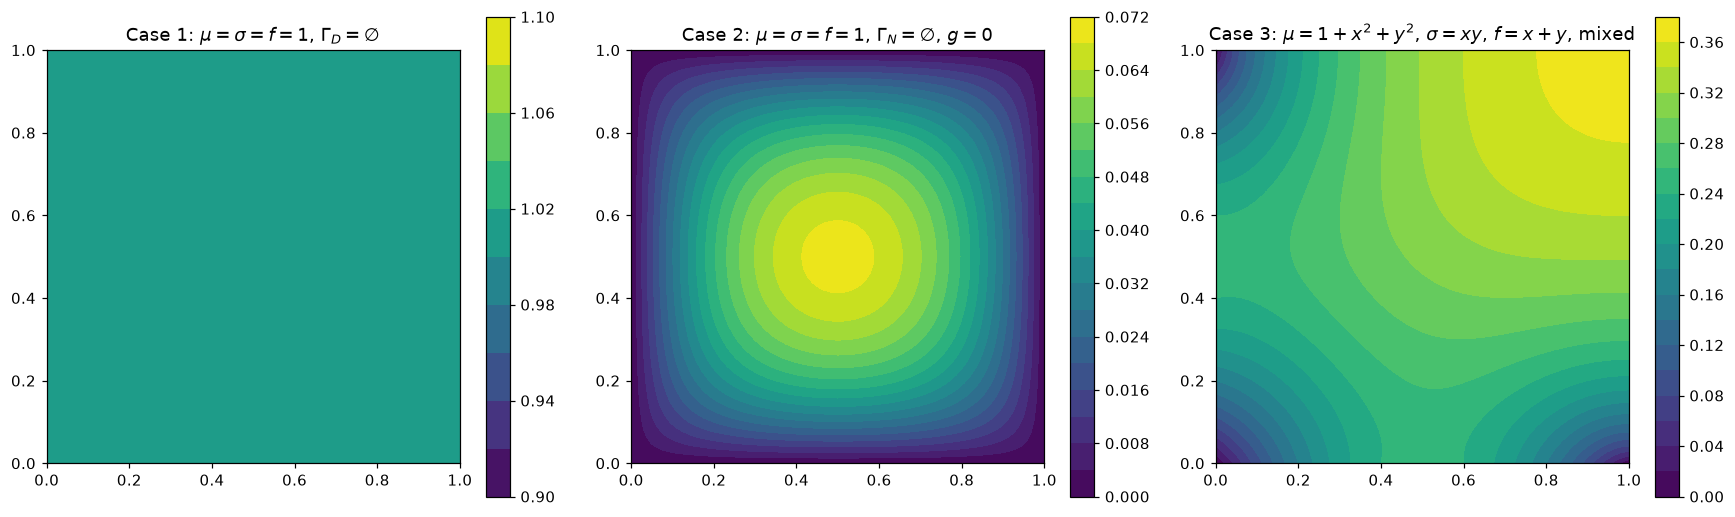

Case 1: min = 1.00000, max = 1.00000
Case 2: min = 0.00000, max = 0.06980
Case 3: min = 0.00000, max = 0.36758
Case 1: max |u_h - 1| = 1.333155807969888e-12


In [6]:
cases = {
    "Case 1: $\\mu=\\sigma=f=1$, $\\Gamma_D=\\emptyset$":
        dict(mu=1.0, sigma=1.0, f=1.0, dirichlet=None),
    "Case 2: $\\mu=\\sigma=f=1$, $\\Gamma_N=\\emptyset$, $g=0$":
        dict(mu=1.0, sigma=1.0, f=1.0,
             dirichlet={s: (lambda x: 0.0) for s in ("left", "right", "bottom", "top")}),
    "Case 3: $\\mu=1+x^2+y^2$, $\\sigma=xy$, $f=x+y$, mixed":
        dict(mu=lambda x: 1 + x[0]**2 + x[1]**2, sigma=lambda x: x[0]*x[1],
             f=lambda x: x[0] + x[1],
             dirichlet={"left": lambda x: x[1]*(1 - x[1]),
                        "bottom": lambda x: x[0]*(1 - x[0])}),
}

mesh = Mesh.UnitarySquareMesh(64, 64, "CG1")
sols = {name: solve_elliptic(mesh, **p) for name, p in cases.items()}

fig, axs = plt.subplots(1, 3, figsize=(16, 4.8))
for i, (ax, (name, uh)) in enumerate(zip(axs, sols.items())):
    # case 1 is the constant 1 up to round-off: fix the scale around it
    uh.plot_contour(ax, title=name, levels=np.linspace(0.9, 1.1, 11) if i == 0 else 20)
plt.tight_layout(); plt.show()

for name, uh in sols.items():
    print(f"{name[:6]}: min = {uh.coeffs.min():.5f}, max = {uh.coeffs.max():.5f}")
print("Case 1: max |u_h - 1| =", np.abs(list(sols.values())[0].coeffs - 1).max())

### Checking the solver

**Case 1** has the exact solution $u\equiv1$ ($\nabla u=0$ and $\sigma u=f$) and $u\equiv 1$ belongs to the $P_1$ space, so the discrete solution must be exact up to round-off (printed above).

**Cases 2 and 3** have no simple closed form. `check_vs_firedrake.py` solves them with Firedrake on the same triangulation (`UnitSquareMesh(16, 16, diagonal="left")`) and compares the nodal values: the largest differences were $1.2\cdot10^{-13}$ (case 1), $2.9\cdot10^{-16}$ (case 2) and $1.2\cdot10^{-15}$ (case 3), i.e. both codes assemble the same linear system. (That script needs Firedrake, so it is not run from this notebook.)

The convergence order is checked with a manufactured solution, $u=\cos(\pi x)\cos(\pi y)$, which satisfies the homogeneous Neumann condition on $\Gamma_{right}\cup\Gamma_{top}$. With the coefficients of case 3,
$f=2\pi x\sin\pi x\cos\pi y+2\pi y\cos\pi x\sin\pi y+(2\pi^2\mu+\sigma)u$, and $g=u$ on $\Gamma_{left}\cup\Gamma_{bottom}$.

   N     L2 error   rate     H1 error   rate
   4    7.397e-02           8.305e-01       
   8    2.023e-02   1.87    4.303e-01   0.95
  16    5.189e-03   1.96    2.173e-01   0.99
  32    1.306e-03   1.99    1.089e-01   1.00
  64    3.272e-04   2.00    5.451e-02   1.00
 128    8.184e-05   2.00    2.726e-02   1.00


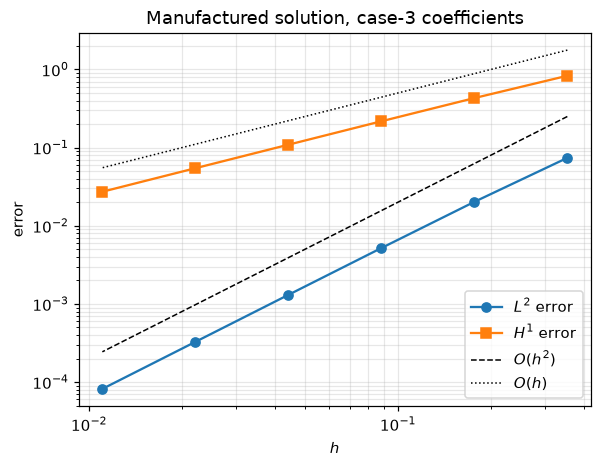

In [7]:
pi = np.pi
u_m = lambda x: np.cos(pi*x[0]) * np.cos(pi*x[1])
gu_m = lambda x: np.array([-pi*np.sin(pi*x[0])*np.cos(pi*x[1]),
                           -pi*np.cos(pi*x[0])*np.sin(pi*x[1])])
mu3 = lambda x: 1 + x[0]**2 + x[1]**2
sig3 = lambda x: x[0]*x[1]
f_m = lambda x: (2*x[0]*pi*np.sin(pi*x[0])*np.cos(pi*x[1])
                 + 2*x[1]*pi*np.cos(pi*x[0])*np.sin(pi*x[1])
                 + (2*pi**2*mu3(x) + sig3(x))*u_m(x))

Ns = [4, 8, 16, 32, 64, 128]
e0, e1 = [], []
for N in Ns:
    m = Mesh.UnitarySquareMesh(N, N, "CG1")
    uh = solve_elliptic(m, mu3, sig3, f_m, {"left": u_m, "bottom": u_m})
    e0.append(L2_error(uh, u_m)); e1.append(H1_error(uh, u_m, gu_m))
e0, e1 = np.array(e0), np.array(e1)
print(f"{'N':>4} {'L2 error':>12} {'rate':>6} {'H1 error':>12} {'rate':>6}")
for i, N in enumerate(Ns):
    r0 = "" if i == 0 else f"{np.log2(e0[i-1]/e0[i]):.2f}"
    r1 = "" if i == 0 else f"{np.log2(e1[i-1]/e1[i]):.2f}"
    print(f"{N:>4} {e0[i]:>12.3e} {r0:>6} {e1[i]:>12.3e} {r1:>6}")

h = np.sqrt(2)/np.array(Ns)
plt.figure(figsize=(6, 4.4))
plt.loglog(h, e0, "o-", label="$L^2$ error"); plt.loglog(h, e1, "s-", label="$H^1$ error")
plt.loglog(h, 2*h**2, "k--", lw=1, label="$O(h^2)$"); plt.loglog(h, 5*h, "k:", lw=1, label="$O(h)$")
plt.xlabel("$h$"); plt.ylabel("error"); plt.grid(True, which="both", alpha=.3)
plt.legend(); plt.title("Manufactured solution, case-3 coefficients"); plt.show()